In [ ]:
# ДЗ 2
# Зашумить изображение при помощи шума гаусса, постоянного шума.
# Протестировать медианный фильтр, фильтр гаусса, билатериальный фильтр, фильтр нелокальных средних с различными параметрами.
# Выяснить, какой фильтр показал лучший результат фильтрации шума.

In [14]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

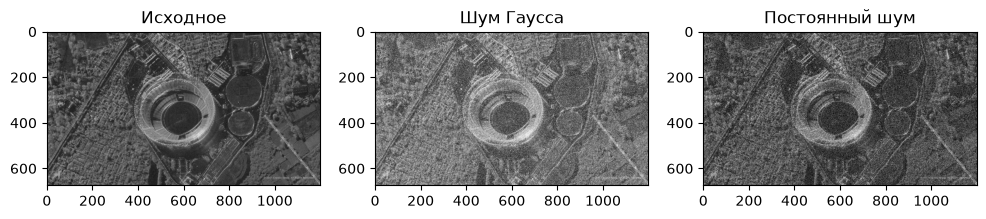

In [15]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_gray, cmap="gray")
plt.title("Исходное")

mean = 0
stddev = 100

noise_gauss = np.zeros(image_gray.shape, np.uint8)
cv2.randn(noise_gauss, mean, stddev)

image_noise_gauss = cv2.add(image_gray, noise_gauss)

plt.subplot(1, 3, 2)
plt.imshow(image_noise_gauss, cmap="gray")
plt.title("Шум Гаусса")

low = -100
high = 100
uniform_noise = np.random.uniform(low, high, image_gray.shape).astype(np.int16)
image_uniform_noise = np.clip(image_gray.astype(np.int16) + uniform_noise, 0, 255).astype(np.uint8)

plt.subplot(1, 3, 3)
plt.imshow(image_uniform_noise, cmap="gray")
plt.title("Постоянный шум")

plt.show()

Зашумленное (Гаусс):       MSE = 4248.95, SSIM = 0.1867
ЛУЧШИЙ фильтр для Гаусса:   Gaussian (k=7, σ=1.0) -> MSE = 1777.82, SSIM = 0.4844
Зашумленное (Равномерный): MSE = 2884.20, SSIM = 0.1789
ЛУЧШИЙ фильтр для Равн.:   Gaussian (k=7, σ=1.0) -> MSE = 360.00, SSIM = 0.5064


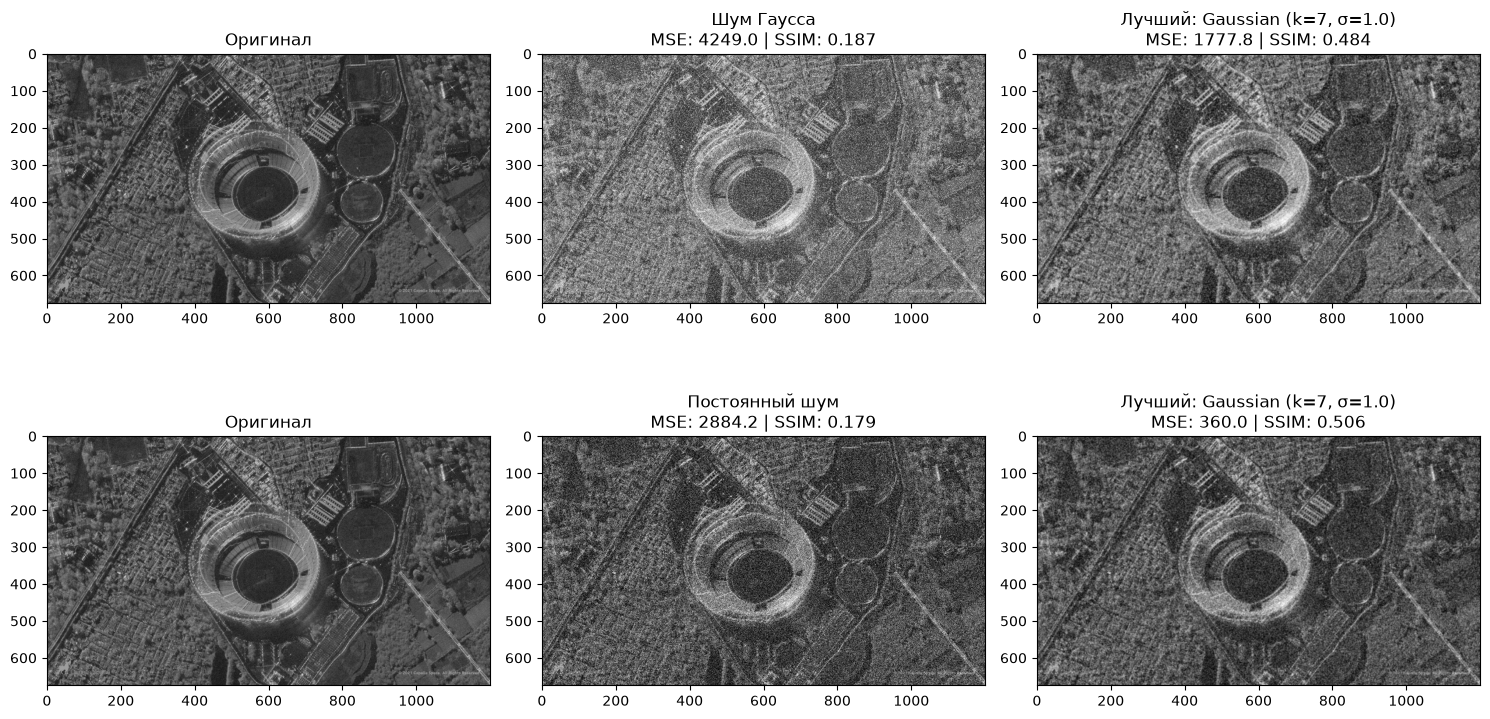

In [22]:
def evaluate_metrics(img_orig, img_filtered):
    """
    Вычисление MSE и SSIM.
    MSE: чем МЕНЬШЕ, тем лучше.
    SSIM: чем БЛИЖЕ К 1.0, тем лучше.
    """
    mse_val = mean_squared_error(img_orig, img_filtered)
    ssim_val = structural_similarity(img_orig, img_filtered)
    return mse_val, ssim_val


def apply_filters(noisy_img, orig_img):
    results = {}
    
    # 1. Медианный фильтр (kernel size должен быть нечетным)
    for ksize in [3, 5, 7]:
        denoised = cv2.medianBlur(noisy_img, ksize)
        mse, ssim = evaluate_metrics(orig_img, denoised)
        results[f'Median (k={ksize})'] = (denoised, mse, ssim)
        
    # 2. Фильтр Гаусса
    for ksize in [3, 5, 7]:
        for sigma in [1.0, 2.0]:
            denoised = cv2.GaussianBlur(noisy_img, (ksize, ksize), sigma)
            mse, ssim = evaluate_metrics(orig_img, denoised)
            results[f'Gaussian (k={ksize}, σ={sigma})'] = (denoised, mse, ssim)
            
    # 3. Билатеральный фильтр
    for d in [5, 9]:
        for sigma_color, sigma_space in [(25, 25), (75, 75)]:
            denoised = cv2.bilateralFilter(noisy_img, d, sigma_color, sigma_space)
            mse, ssim = evaluate_metrics(orig_img, denoised)
            results[f'Bilateral (d={d}, σc={sigma_color})'] = (denoised, mse, ssim)
            
    # 4. Фильтр нелокальных средних (Non-Local Means)
    for h in [10, 15, 20]:
        denoised = cv2.fastNlMeansDenoising(noisy_img, None, h=h, templateWindowSize=7, searchWindowSize=21)
        mse, ssim = evaluate_metrics(orig_img, denoised)
        results[f'NL-Means (h={h})'] = (denoised, mse, ssim)
        
    return results

results_gauss = apply_filters(image_noise_gauss, image_gray)
results_uniform = apply_filters(image_uniform_noise, image_gray)


def get_best_result(results_dict):
    # Выбираем лучший результат по максимальному значению SSIM
    best_key = max(results_dict, key=lambda x: results_dict[x][2])
    return best_key, results_dict[best_key][0], results_dict[best_key][1], results_dict[best_key][2]

best_g_name, best_g_img, best_g_mse, best_g_ssim = get_best_result(results_gauss)
best_u_name, best_u_img, best_u_mse, best_u_ssim = get_best_result(results_uniform)

init_g_mse, init_g_ssim = evaluate_metrics(image_gray, image_noise_gauss)
init_u_mse, init_u_ssim = evaluate_metrics(image_gray, image_uniform_noise)

print("=" * 70)
print(f"Зашумленное (Гаусс):       MSE = {init_g_mse:.2f}, SSIM = {init_g_ssim:.4f}")
print(f"ЛУЧШИЙ фильтр для Гаусса:   {best_g_name} -> MSE = {best_g_mse:.2f}, SSIM = {best_g_ssim:.4f}")
print("=" * 70)
print(f"Зашумленное (Равномерный): MSE = {init_u_mse:.2f}, SSIM = {init_u_ssim:.4f}")
print(f"ЛУЧШИЙ фильтр для Равн.:   {best_u_name} -> MSE = {best_u_mse:.2f}, SSIM = {best_u_ssim:.4f}")
print("=" * 70)

plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(image_gray, cmap="gray")
plt.title("Оригинал")

plt.subplot(2, 3, 2)
plt.imshow(image_noise_gauss, cmap="gray")
plt.title(f"Шум Гаусса\nMSE: {init_g_mse:.1f} | SSIM: {init_g_ssim:.3f}")

plt.subplot(2, 3, 3)
plt.imshow(best_g_img, cmap="gray")
plt.title(f"Лучший: {best_g_name}\nMSE: {best_g_mse:.1f} | SSIM: {best_g_ssim:.3f}")


plt.subplot(2, 3, 4)
plt.imshow(image_gray, cmap="gray")
plt.title("Оригинал")

plt.subplot(2, 3, 5)
plt.imshow(image_uniform_noise, cmap="gray")
plt.title(f"Постоянный шум\nMSE: {init_u_mse:.1f} | SSIM: {init_u_ssim:.3f}")

plt.subplot(2, 3, 6)
plt.imshow(best_u_img, cmap="gray")
plt.title(f"Лучший: {best_u_name}\nMSE: {best_u_mse:.1f} | SSIM: {best_u_ssim:.3f}")

plt.tight_layout()
plt.show()